Importing necessary

In [105]:
import os
import math
import re
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer

#for preprocessing and Feature engineering
from sklearn.impute import (
    SimpleImputer,
    KNNImputer
)

from sklearn.feature_selection import (
    SelectKBest,
    SelectPercentile,
    RFE,
    RFECV,
    VarianceThreshold
)

from sklearn.preprocessing import (
    OneHotEncoder,
    MinMaxScaler,
    StandardScaler,
    RobustScaler,
    Normalizer,
    PolynomialFeatures,
    OrdinalEncoder,
    LabelEncoder,
    KBinsDiscretizer,
    FunctionTransformer
)

#Model Selection and Evaluation

from sklearn.model_selection import (
    train_test_split,
    cross_val_predict,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    KFold,
    cross_validate
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_curve,
    roc_auc_score,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    root_mean_squared_error,
    confusion_matrix,
    r2_score,
    classification_report,
    f1_score,
    recall_score,
    explained_variance_score,
    precision_score
)

#fro regression
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    BayesianRidge,
    SGDRegressor,
    PassiveAggressiveRegressor
)

from sklearn.tree import(
    DecisionTreeRegressor
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    ExtraTreesRegressor,
    BaggingRegressor
)

from sklearn.svm import (
    SVR,
    LinearSVR
)

from sklearn.neighbors import(
    KNeighborsRegressor
)

from sklearn.neural_network import(
    MLPRegressor,
    _multilayer_perceptron
)

#for Classification
from sklearn.linear_model import(
    LogisticRegression,
    RidgeClassifier,
    Perceptron,
    PassiveAggressiveClassifier,
    SGDClassifier
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import(
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    ExtraTreesClassifier,
    BaggingClassifier
)

from sklearn.svm import (
    SVC,
    LinearSVC,
    NuSVC
)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB,
    BernoulliNB,
    CategoricalNB,
    ComplementNB
)

from sklearn.neural_network import MLPClassifier

from sklearn.discriminant_analysis import(
    QuadraticDiscriminantAnalysis,
    LinearDiscriminantAnalysis
)

from sklearn.impute import IterativeImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

import scipy.stats as stas

from scipy.stats import (
    anderson,
    jarque_bera,
    shapiro,
    normaltest,
    kstest
)

from statsmodels.stats.diagnostic import lilliefors

from scipy.stats import zscore

from sklearn.feature_extraction import FeatureHasher

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.base import BaseEstimator, TransformerMixin


### Loading Datasets

In [106]:
path= os.path.join('..','data','raw','used_cars.csv')
print(path)

..\data\raw\used_cars.csv


In [107]:
df=pd.read_csv(path)

#### Basic Initial Inspection

In [108]:
pd.set_option('display.max_rows',None)
pd.set_option('display.max_columns',None)
pd.set_option('display.max_colwidth',None)
df.head(1)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"


In [109]:
df.tail(1)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
4008,BMW,X3 xDrive30i,2020,"43,000 mi.",Gasoline,248.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,A/T,Gray,Brown,At least 1 accident or damage reported,Yes,"$40,000"


In [110]:
df.sample()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
2892,Chevrolet,Corvette Base,2007,"4,048 mi.",Gasoline,400.0HP 6.0L 8 Cylinder Engine Gasoline Fuel,6-Speed M/T,Yellow,Gray,None reported,Yes,"$38,000"


In [111]:
df.describe(include='all')

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
count,4009,4009,4009.000000,4009,3839,4009,4009,4009,4009,3896,3413,4009
unique,57,1898,NaN,2818,7,1146,62,319,156,2,1,1569
top,Ford,M3 Base,NaN,"110,000 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,A/T,Black,Black,None reported,Yes,"$15,000"
freq,386,30,NaN,16,3309,52,1037,905,2025,2910,3413,39
mean,NaN,NaN,2015.515590,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,6.104816,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,1974.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,2012.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,2020.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [112]:
print(f'The memory consumed in RAM is {(df.memory_usage(deep=True)/(1024*1024)).sum():.3f} MB')

The memory consumed in RAM is 2.584 MB


In [113]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB


In [114]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [115]:
df['milage']=(
    df['milage']
    .str.replace(',','')
    .str.replace('mi.','')
    .astype(float)
)

In [116]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [117]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         4009 non-null   str    
 1   model         4009 non-null   str    
 2   model_year    4009 non-null   int64  
 3   milage        4009 non-null   float64
 4   fuel_type     3839 non-null   str    
 5   engine        4009 non-null   str    
 6   transmission  4009 non-null   str    
 7   ext_col       4009 non-null   str    
 8   int_col       4009 non-null   str    
 9   accident      3896 non-null   str    
 10  clean_title   3413 non-null   str    
 11  price         4009 non-null   str    
dtypes: float64(1), int64(1), str(10)
memory usage: 376.0 KB


In [118]:
df['price']=(
    df['price']
    .str.replace('$','')
    .str.replace(',','')
    .astype(float)
)

In [119]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         4009 non-null   str    
 1   model         4009 non-null   str    
 2   model_year    4009 non-null   int64  
 3   milage        4009 non-null   float64
 4   fuel_type     3839 non-null   str    
 5   engine        4009 non-null   str    
 6   transmission  4009 non-null   str    
 7   ext_col       4009 non-null   str    
 8   int_col       4009 non-null   str    
 9   accident      3896 non-null   str    
 10  clean_title   3413 non-null   str    
 11  price         4009 non-null   float64
dtypes: float64(2), int64(1), str(9)
memory usage: 376.0 KB


In [120]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0


In [121]:
df['Accident_Occured']=(
    df['accident']
    .apply(lambda x: "NO"if x=="None reported" else "YES")
)

In [122]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occured
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO


In [123]:
df['Engine_Capacity']=(
    df['engine']
    .str.extract(r'(\d+\.\d+L|\d+\.\s\d+L|\d+\.\d\s+Liter|\d+\s+Liter)')
)

In [124]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occured,Engine_Capacity
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7L
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8L
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO,3.5 Liter
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5L
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO,2.0L


In [125]:
df['Horse_Power']=(
    df['engine']
    .str.extract(r'(\d+\.\d+HP|\d+HP)')
)

In [126]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occured,Engine_Capacity,Horse_Power
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7L,300.0HP
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8L,NaN
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO,3.5 Liter,NaN
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5L,354.0HP
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO,2.0L,NaN


In [127]:
df['Engine_Capacity']=(
    df['Engine_Capacity']
    .str.replace('Liter','')
    .str.replace('L','')
    .astype(float)
)

In [128]:
df['Horse_Power']=(
    df['Horse_Power']
    .str.replace('HP','')
    .astype(float)
)

In [129]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occured,Engine_Capacity,Horse_Power
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7,300.0
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8,NaN
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO,3.5,NaN
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5,354.0
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO,2.0,NaN


#### Handling Missing Values

In [130]:
df.isnull().sum()

brand                 0
model                 0
model_year            0
milage                0
fuel_type           170
engine                0
transmission          0
ext_col               0
int_col               0
accident            113
clean_title         596
price                 0
Accident_Occured      0
Engine_Capacity     238
Horse_Power         808
dtype: int64

In [131]:
missing_info={}
for col in df.columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage are:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage are:

fuel_type:4.24%
accident:2.82%
clean_title:14.87%
Engine_Capacity:5.94%
Horse_Power:20.15%


In [132]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occured,Engine_Capacity,Horse_Power
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7,300.0
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8,NaN
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO,3.5,NaN
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5,354.0
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO,2.0,NaN


In [133]:
Categorical_Columns=df.select_dtypes(include=['object','category']).columns
Numerical_Columns=df.select_dtypes(include=['number','int64','int32','float64','float32']).columns

C:\Users\Dell\AppData\Local\Temp\ipykernel_29016\3997355665.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Categorical_Columns=df.select_dtypes(include=['object','category']).columns


In [134]:
df[Categorical_Columns].head()

,brand,model,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,Accident_Occured
0,Ford,Utility Police Interceptor Base,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,YES
1,Hyundai,Palisade SEL,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,YES
2,Lexus,RX 350 RX 350,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,NO
3,INFINITI,Q50 Hybrid Sport,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,NO
4,Audi,Q3 45 S line Premium Plus,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,NO


In [135]:
df[Numerical_Columns].head()

,model_year,milage,price,Engine_Capacity,Horse_Power
0,2013,51000.0,10300.0,3.7,300.0
1,2021,34742.0,38005.0,3.8,NaN
2,2022,22372.0,54598.0,3.5,NaN
3,2015,88900.0,15500.0,3.5,354.0
4,2021,9835.0,34999.0,2.0,NaN


In [136]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

fuel_type:4.24%
accident:2.82%
clean_title:14.87%


In [137]:
df['clean_title'].value_counts()

clean_title
Yes    3413
Name: count, dtype: int64

In [138]:
df['clean_title'].head()

0    Yes
1    Yes
2    NaN
3    Yes
4    NaN
Name: clean_title, dtype: str

In [139]:
df['clean_title']=df['clean_title'].fillna('Unknown')

In [140]:
df['clean_title'].head()

0        Yes
1        Yes
2    Unknown
3        Yes
4    Unknown
Name: clean_title, dtype: str

In [141]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

fuel_type:4.24%
accident:2.82%


In [142]:
df[['brand','engine','model','transmission','fuel_type']].head(50)

,brand,engine,model,transmission,fuel_type
0,Ford,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,Utility Police Interceptor Base,6-Speed A/T,E85 Flex Fuel
1,Hyundai,3.8L V6 24V GDI DOHC,Palisade SEL,8-Speed Automatic,Gasoline
2,Lexus,3.5 Liter DOHC,RX 350 RX 350,Automatic,Gasoline
3,INFINITI,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,Q50 Hybrid Sport,7-Speed A/T,Hybrid
4,Audi,2.0L I4 16V GDI DOHC Turbo,Q3 45 S line Premium Plus,8-Speed Automatic,Gasoline
5,Acura,2.4 Liter,ILX 2.4L,F,Gasoline
6,Audi,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,S3 2.0T Premium Plus,6-Speed A/T,Gasoline
7,BMW,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,740 iL,A/T,Gasoline
8,Lexus,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,RC 350 F Sport,6-Speed A/T,Gasoline
9,Tesla,534.0HP Electric Motor Electric Fuel System,Model X Long Range Plus,A/T,NaN


In [143]:
df.loc[df['engine'].str.contains('Electric Motor Electric Fuel System',case=False,na= False),['brand','model','engine','transmission','fuel_type']]

,brand,model,engine,transmission,fuel_type
9,Tesla,Model X Long Range Plus,534.0HP Electric Motor Electric Fuel System,A/T,NaN
44,Lucid,Air Grand Touring,536.0HP Electric Motor Electric Fuel System,1-Speed A/T,NaN
68,Lucid,Air Grand Touring,536.0HP Electric Motor Electric Fuel System,1-Speed A/T,NaN
92,Rivian,R1S Adventure Package,835.0HP Electric Motor Electric Fuel System,1-Speed A/T,NaN
122,Rivian,R1S Adventure Package,835.0HP Electric Motor Electric Fuel System,A/T,NaN
129,Lucid,Air Pure,620.0HP Electric Motor Electric Fuel System,A/T,NaN
155,Tesla,Model 3 Performance,455.0HP Electric Motor Electric Fuel System,A/T,NaN
189,Tesla,Model Y Performance,455.0HP Electric Motor Electric Fuel System,1-Speed A/T,NaN
225,Tesla,Model X Base,670.0HP Electric Motor Electric Fuel System,A/T,NaN
253,Mercedes-Benz,EQS 450 4MATIC,355.0HP Electric Motor Electric Fuel System,1-Speed A/T,NaN


In [144]:
df['fuel_type']=(
    df['fuel_type']
    .where(~df['engine']
           .str.contains('Electric Motor Electric Fuel System',case=False,na= False),
           df['fuel_type'].fillna('Electric'))
)

In [145]:
df.loc[df['engine'].str.contains('Electric Motor Electric Fuel System',case=False,na= False),['brand','model','engine','transmission','fuel_type']]

,brand,model,engine,transmission,fuel_type
9,Tesla,Model X Long Range Plus,534.0HP Electric Motor Electric Fuel System,A/T,Electric
44,Lucid,Air Grand Touring,536.0HP Electric Motor Electric Fuel System,1-Speed A/T,Electric
68,Lucid,Air Grand Touring,536.0HP Electric Motor Electric Fuel System,1-Speed A/T,Electric
92,Rivian,R1S Adventure Package,835.0HP Electric Motor Electric Fuel System,1-Speed A/T,Electric
122,Rivian,R1S Adventure Package,835.0HP Electric Motor Electric Fuel System,A/T,Electric
129,Lucid,Air Pure,620.0HP Electric Motor Electric Fuel System,A/T,Electric
155,Tesla,Model 3 Performance,455.0HP Electric Motor Electric Fuel System,A/T,Electric
189,Tesla,Model Y Performance,455.0HP Electric Motor Electric Fuel System,1-Speed A/T,Electric
225,Tesla,Model X Base,670.0HP Electric Motor Electric Fuel System,A/T,Electric
253,Mercedes-Benz,EQS 450 4MATIC,355.0HP Electric Motor Electric Fuel System,1-Speed A/T,Electric


In [146]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

fuel_type:0.6%
accident:2.82%


In [147]:
df.loc[df['fuel_type'].isnull(),['brand','model','transmission','engine','fuel_type']]

,brand,model,transmission,engine,fuel_type
236,Polestar,2 Launch Edition,1-Speed Automatic,Electric,NaN
321,Chevrolet,Bolt EUV Premier,1-Speed Automatic,Electric,NaN
383,Ford,Mustang Mach-E Select,Automatic,Standard Range Battery,NaN
456,Kia,EV6 Wind,Automatic,111.2Ah / FR 70kW / RR 160kW (697V),NaN
555,Tesla,Model 3 Long Range,Automatic,Dual Motor - Standard,NaN
962,Audi,e-tron Prestige,1-Speed Automatic,Electric,NaN
981,Audi,e-tron Premium,1-Speed Automatic,Electric,NaN
1007,Tesla,Model Y Performance,1-Speed Automatic,Electric,NaN
1221,Toyota,bZ4X Limited,Automatic,Electric,NaN
1228,Tesla,Model X Performance,1-Speed Automatic,Electric,NaN


In [148]:
df['fuel_type']=(
    df['fuel_type']
    .where(~df['engine']
           .str.contains('Electric',case=False,na= False),
           df['fuel_type'].fillna('Electric'))
)

In [149]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

fuel_type:0.12%
accident:2.82%


In [150]:
df['fuel_type']=(
    df['fuel_type']
    .where(~df['brand']
           .str.contains('Tesla',case=False,na= False),
           df['fuel_type'].fillna('Electric'))
)

In [151]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

fuel_type:0.05%
accident:2.82%


In [152]:
df['fuel_type']=(
    df['fuel_type']
    .where(~df['engine']
           .str.contains('Battery',case=False,na= False),
           df['fuel_type'].fillna('Electric'))
)

In [153]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

fuel_type:0.02%
accident:2.82%


In [154]:
df['fuel_type']=(
    df['fuel_type']
    .where(~df['engine']
           .str.contains('111.2Ah / FR 70kW / RR 160kW (697V)',case=False,na= False),
           df['fuel_type'].fillna('Electric'))
)

C:\Users\Dell\AppData\Local\Temp\ipykernel_29016\3950936161.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains('111.2Ah / FR 70kW / RR 160kW (697V)',case=False,na= False),


In [155]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

fuel_type:0.02%
accident:2.82%


In [156]:
df.loc[df['fuel_type'].isnull(),['brand','model','transmission','engine','fuel_type']]

,brand,model,transmission,engine,fuel_type
456,Kia,EV6 Wind,Automatic,111.2Ah / FR 70kW / RR 160kW (697V),NaN


In [157]:
df['fuel_type']=(
    df['fuel_type']
    .where(~df['model']
           .str.contains('EV6 Wind',case=False,na= False),
           df['fuel_type'].fillna('Electric'))
)

In [158]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

accident:2.82%


In [159]:
df[['brand','engine','model','fuel_type','accident','clean_title']][df['accident'].isnull()]

,brand,engine,model,fuel_type,accident,clean_title
20,Genesis,375.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,GV70 3.5T Sport,Gasoline,NaN,Unknown
89,Subaru,165.0HP 2.5L 4 Cylinder Engine Gasoline Fuel,Forester 2.5 X,Gasoline,NaN,Unknown
128,Audi,280.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,Q7 3.0T Premium Plus,Gasoline,NaN,Unknown
129,Lucid,620.0HP Electric Motor Electric Fuel System,Air Pure,Electric,NaN,Unknown
131,Audi,265.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,TTS 2.0T Premium Plus,Gasoline,NaN,Unknown
139,Porsche,400.0HP 3.8L Flat 6 Cylinder Engine Gasoline Fuel,911 Carrera S,Gasoline,NaN,Unknown
224,Maserati,404.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,Ghibli S Q4,Gasoline,NaN,Unknown
235,BMW,560.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,M6 Base,Gasoline,NaN,Unknown
357,Mercedes-Benz,188.0HP 3.0L V6 Cylinder Engine Diesel Fuel,Sprinter 4500 High Roof,Diesel,NaN,Unknown
376,Hyundai,2.5L I4 16V PDI DOHC,Santa Fe SEL,Gasoline,NaN,Unknown


In [160]:
df['accident']= df['accident'].fillna('Unknown')

In [161]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occured,Engine_Capacity,Horse_Power
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7,300.0
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8,NaN
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Unknown,54598.0,NO,3.5,NaN
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5,354.0
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Unknown,34999.0,NO,2.0,NaN


In [162]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:



In [163]:
missing_info={}
for col in Numerical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

Engine_Capacity:5.94%
Horse_Power:20.15%


In [164]:
df[['brand','engine','model','fuel_type','Engine_Capacity','accident','clean_title']][df['Engine_Capacity'].isnull()]

,brand,engine,model,fuel_type,Engine_Capacity,accident,clean_title
9,Tesla,534.0HP Electric Motor Electric Fuel System,Model X Long Range Plus,Electric,NaN,None reported,Yes
10,Land,V6,Rover Range Rover Sport 3.0 Supercharged HST,Gasoline,NaN,None reported,Unknown
32,BMW,120 AH,i3 120Ah w/Range Extender,Hybrid,NaN,None reported,Unknown
44,Lucid,536.0HP Electric Motor Electric Fuel System,Air Grand Touring,Electric,NaN,None reported,Yes
68,Lucid,536.0HP Electric Motor Electric Fuel System,Air Grand Touring,Electric,NaN,None reported,Yes
92,Rivian,835.0HP Electric Motor Electric Fuel System,R1S Adventure Package,Electric,NaN,None reported,Yes
120,Land,V6,Rover Range Rover Sport 3.0L Supercharged HSE,Gasoline,NaN,At least 1 accident or damage reported,Unknown
122,Rivian,835.0HP Electric Motor Electric Fuel System,R1S Adventure Package,Electric,NaN,None reported,Yes
129,Lucid,620.0HP Electric Motor Electric Fuel System,Air Pure,Electric,NaN,Unknown,Unknown
130,Chrysler,–,Pacifica Touring,–,NaN,None reported,Yes


In [165]:
df[df['Engine_Capacity'].isnull()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occured,Engine_Capacity,Horse_Power
9,Tesla,Model X Long Range Plus,2020,34000.0,Electric,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,None reported,Yes,69950.0,NO,NaN,534.0
10,Land,Rover Range Rover Sport 3.0 Supercharged HST,2021,27608.0,Gasoline,V6,Automatic,Fuji White,Pimento / Ebony,None reported,Unknown,73897.0,NO,NaN,NaN
32,BMW,i3 120Ah w/Range Extender,2020,35035.0,Hybrid,120 AH,Automatic,Black,Black,None reported,Unknown,24998.0,NO,NaN,NaN
44,Lucid,Air Grand Touring,2022,3552.0,Electric,536.0HP Electric Motor Electric Fuel System,1-Speed A/T,Red,Beige,None reported,Yes,119999.0,NO,NaN,536.0
68,Lucid,Air Grand Touring,2022,4900.0,Electric,536.0HP Electric Motor Electric Fuel System,1-Speed A/T,Red,Black,None reported,Yes,99000.0,NO,NaN,536.0
92,Rivian,R1S Adventure Package,2023,2800.0,Electric,835.0HP Electric Motor Electric Fuel System,1-Speed A/T,White,Green,None reported,Yes,92000.0,NO,NaN,835.0
120,Land,Rover Range Rover Sport 3.0L Supercharged HSE,2018,104700.0,Gasoline,V6,Automatic,Fuji White,Ivory / Ebony,At least 1 accident or damage reported,Unknown,30775.0,YES,NaN,NaN
122,Rivian,R1S Adventure Package,2023,2500.0,Electric,835.0HP Electric Motor Electric Fuel System,A/T,Green,White,None reported,Yes,94000.0,NO,NaN,835.0
129,Lucid,Air Pure,2023,1300.0,Electric,620.0HP Electric Motor Electric Fuel System,A/T,Black,Gray,Unknown,Unknown,86900.0,YES,NaN,620.0
130,Chrysler,Pacifica Touring,2017,87305.0,–,–,9-Speed A/T,Silver,Black,None reported,Yes,9000.0,NO,NaN,NaN


In [166]:
df['Engine_Capacity'] = df['Engine_Capacity'].where(
    ~df['transmission'].str.contains('A/T|Automatic|Auto|M/T', case=False, na=False),
    df['Engine_Capacity'].fillna(0)
)

In [167]:
missing_info={}
for col in Numerical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

Engine_Capacity:0.2%
Horse_Power:20.15%


In [168]:
df[['brand','engine','model','fuel_type','Engine_Capacity','transmission','accident','clean_title']][df['Engine_Capacity'].isnull()]

,brand,engine,model,fuel_type,Engine_Capacity,transmission,accident,clean_title
855,Ford,–,Bronco,–,NaN,–,None reported,Yes
923,Dodge,–,Challenger R/T,–,NaN,Transmission w/Dual Shift Mode,None reported,Yes
1241,Porsche,Dual AC Electric Motors,Taycan Turbo,Electric,NaN,Single-Speed Fixed Gear,None reported,Unknown
1615,Rolls-Royce,–,Phantom,–,NaN,–,None reported,Yes
2125,Subaru,"2L H-4 gasoline direct injection, DOHC, variable valve control,",Impreza Premium,Gasoline,NaN,Variable,At least 1 accident or damage reported,Unknown
2333,Subaru,"2L H-4 DOHC, variable valve control, regular unleaded, engine wi",Impreza 2.0i,Gasoline,NaN,Manual,At least 1 accident or damage reported,Unknown
3091,Porsche,"4L H-6 gasoline direct injection, DOHC, VarioCam Plus variable v",911 GT3,Gasoline,NaN,"Manual, 6-Spd",None reported,Unknown
3918,Porsche,–,911 Carrera Cabriolet,–,NaN,Transmission w/Dual Shift Mode,Unknown,Unknown


C:\Users\Dell\AppData\Local\Temp\ipykernel_29016\699070109.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(rect=[0,0.97,1,1])


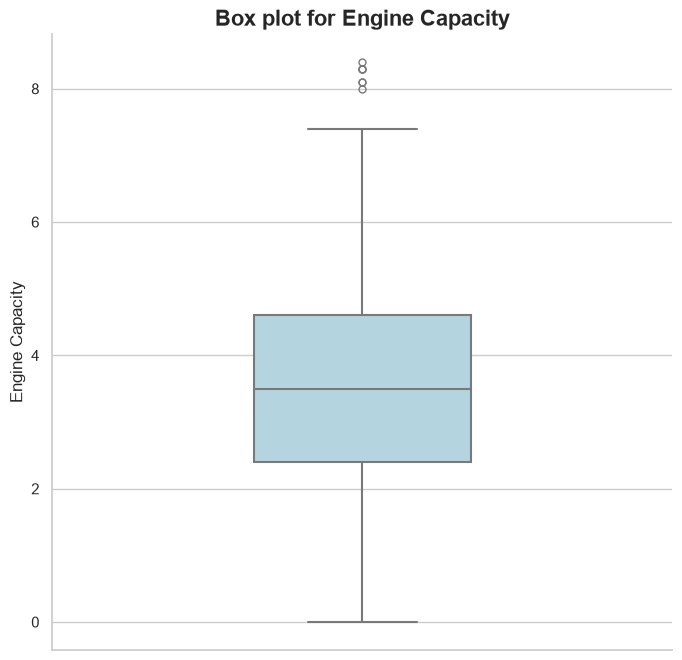

In [169]:
sns.set_theme(style='whitegrid')

fig,axes=plt.subplots(figsize=(8,8))

sns.boxplot(
    y=df['Engine_Capacity'],
    color="lightblue",
    width=0.35,
    linewidth=1.5,
    fliersize=5,
    ax=axes
)

axes.set_title("Box plot for Engine Capacity", fontsize=16, fontweight='bold')
axes.set_ylabel("Engine Capacity")
axes.set_xlabel("")

sns.despine()
plt.tight_layout(rect=[0,0.97,1,1])
plt.show()

In [170]:
df['Engine_Capacity']=df['Engine_Capacity'].fillna(df['Engine_Capacity'].median())

In [171]:
missing_info={}
for col in Numerical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

Horse_Power:20.15%


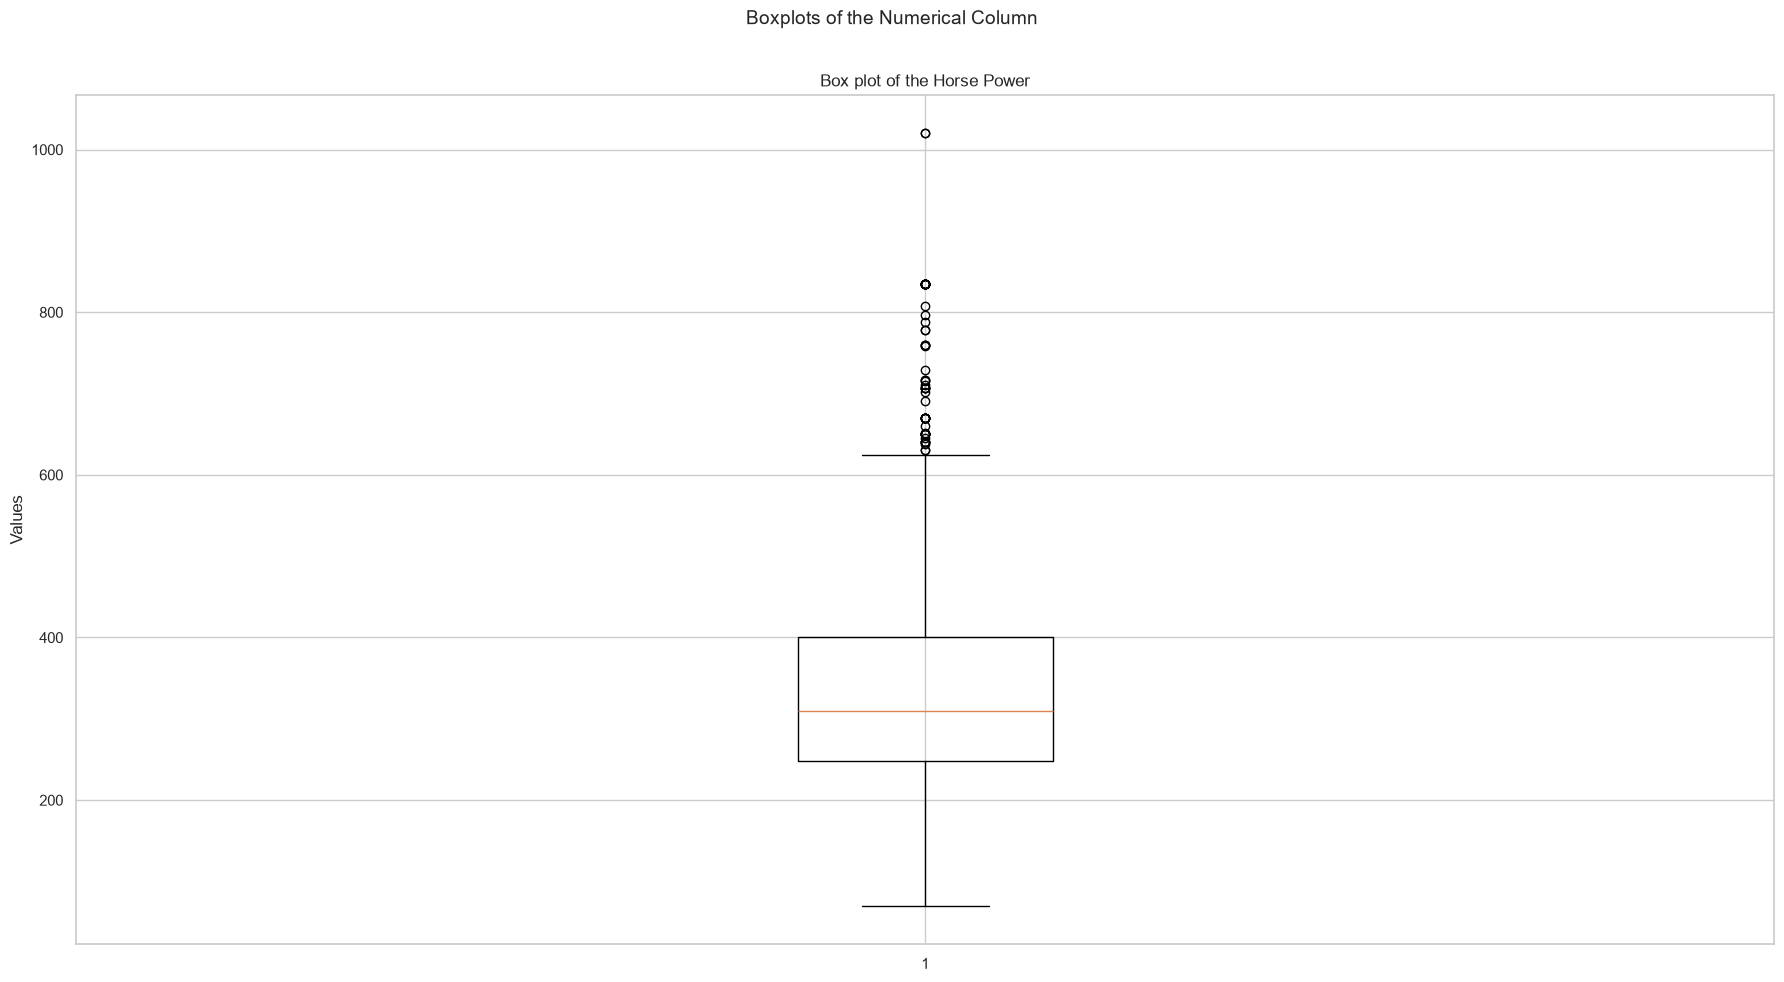

In [172]:
fig, axes = plt.subplots(figsize=(18,10))
axes.boxplot(df['Horse_Power'].dropna())
axes.set_title("Box plot of the Horse Power")
axes.set_ylabel("Values")
plt.suptitle("Boxplots of the Numerical Column", fontsize =14)
plt.tight_layout(rect=[0,0,1,0.97])
plt.show()

In [173]:
skew_value = df['Horse_Power'].skew()
print(f'The skewness of the Horse Power is: {skew_value:.3f}')

The skewness of the Horse Power is: 0.947


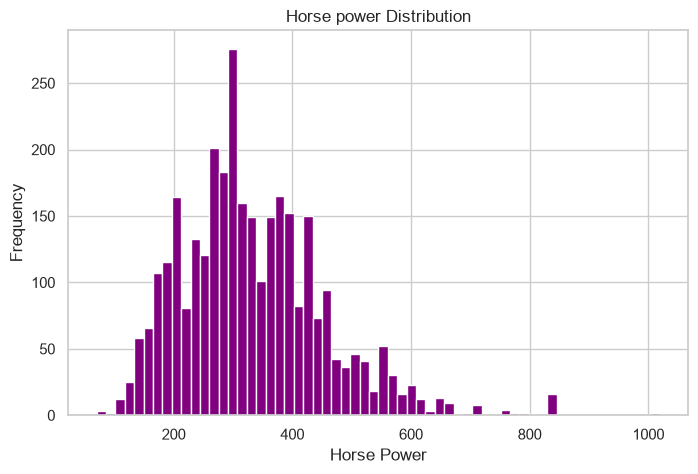

In [174]:
fig, axes = plt.subplots(figsize=(8,5))
axes.hist(df['Horse_Power'].dropna(),bins=60,color='purple')
axes.set_title('Horse power Distribution')
axes.set_xlabel("Horse Power")
axes.set_ylabel("Frequency")
plt.show()

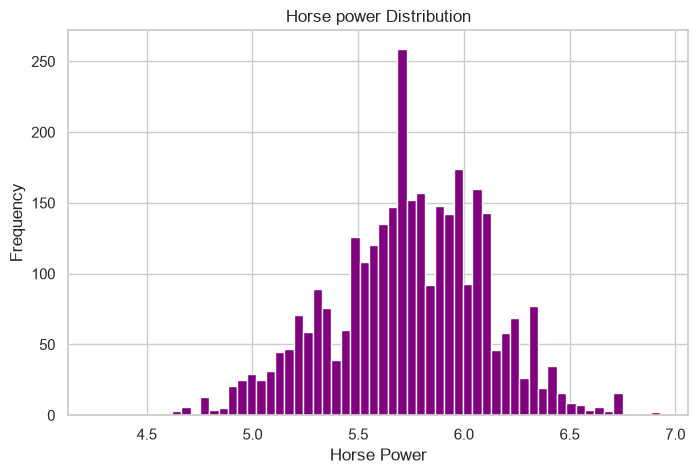

In [175]:
fig, axes = plt.subplots(figsize=(8,5))
axes.hist(np.log1p(df['Horse_Power']).dropna(),bins=60,color='purple')
axes.set_title('Horse power Distribution')
axes.set_xlabel("Horse Power")
axes.set_ylabel("Frequency")
plt.show()

In [176]:
missing_info={}
for col in Numerical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:

Horse_Power:20.15%


In [177]:
numeric_cols = ['Engine_Capacity','model_year','milage','Horse_Power','price']
df[numeric_cols]=df[numeric_cols].apply(pd.to_numeric,errors='coerce')

known=df[df['Horse_Power'].notna()]
missing=df[df['Horse_Power'].isna()]

numerical_features=['Engine_Capacity','model_year','milage','price']
categorical_features=['brand']

preprocessor=ColumnTransformer(
    transformers=[
('cat',OneHotEncoder(handle_unknown='ignore'),categorical_features)
    ],
remainder='passthrough'
)

pipeline=Pipeline(steps=[
    ('preprocessors',preprocessor),

    ('regressor',LinearRegression())
])


pipeline.fit(
    known[categorical_features+numerical_features],
    known['Horse_Power']
)

predicted_horsepower=pipeline.predict(missing[categorical_features+numerical_features])

df.loc[df['Horse_Power'].isna(),'Horse_Power']=predicted_horsepower

df['Horse_Power']=df['Horse_Power'].clip(lower=0)

print("All the missing values are filled with the linear regression imputation technique.")

All the missing values are filled with the linear regression imputation technique.


In [178]:
missing_info={}
for col in Numerical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:



In [179]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with the missing percentage is:\n")
for col, per in missing_info.items():
    print(f"{col}:{per}%")



 The columns with the missing percentage is:



In [180]:
df.duplicated().sum()

np.int64(0)

#### Outliers Detection

Outliers for the numerical columns

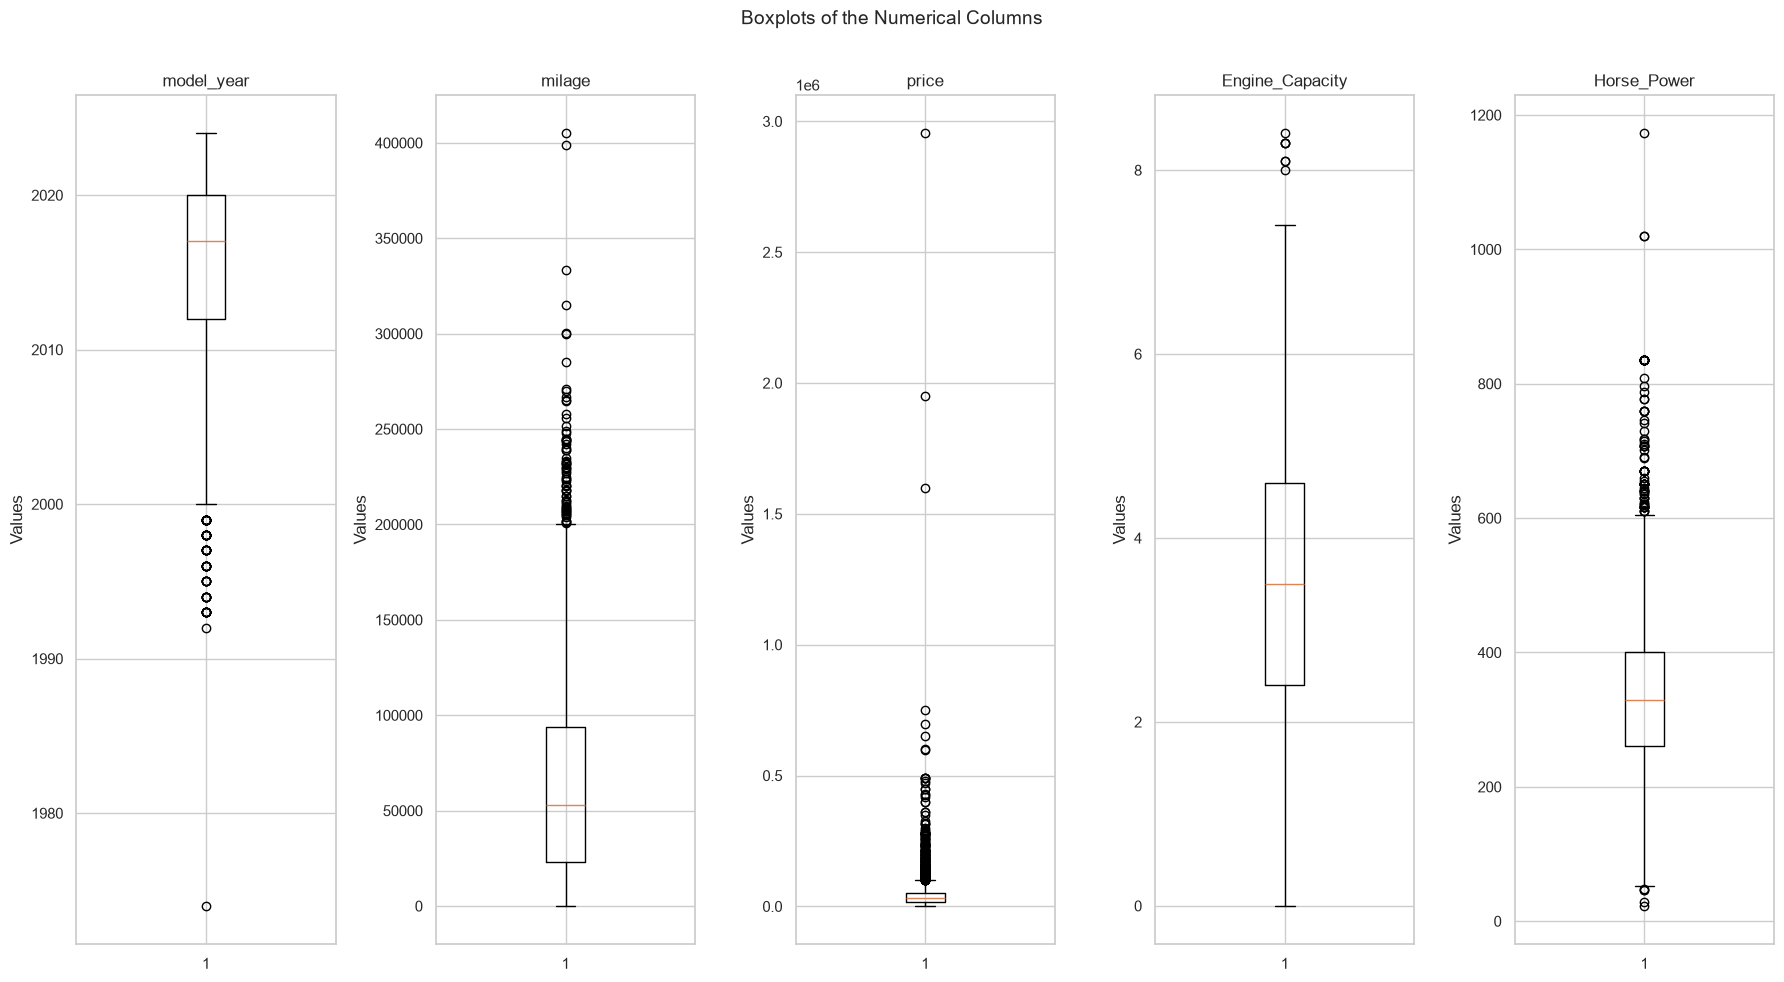

In [181]:
fig, axes=plt.subplots(1,5,figsize=(18,10))

for i, cols in enumerate(Numerical_Columns):
    axes[i].boxplot(df[cols].dropna())
    axes[i].set_title(cols)
    axes[i].set_ylabel("Values")

plt.suptitle("Boxplots of the Numerical Columns", fontsize=14)
plt.tight_layout(rect=[0,0,1,0.97])
plt.show()

### Procedure to Remove Outliers from the Numerical columns (if neccessary)

Histogram with kde and Q-Q plots

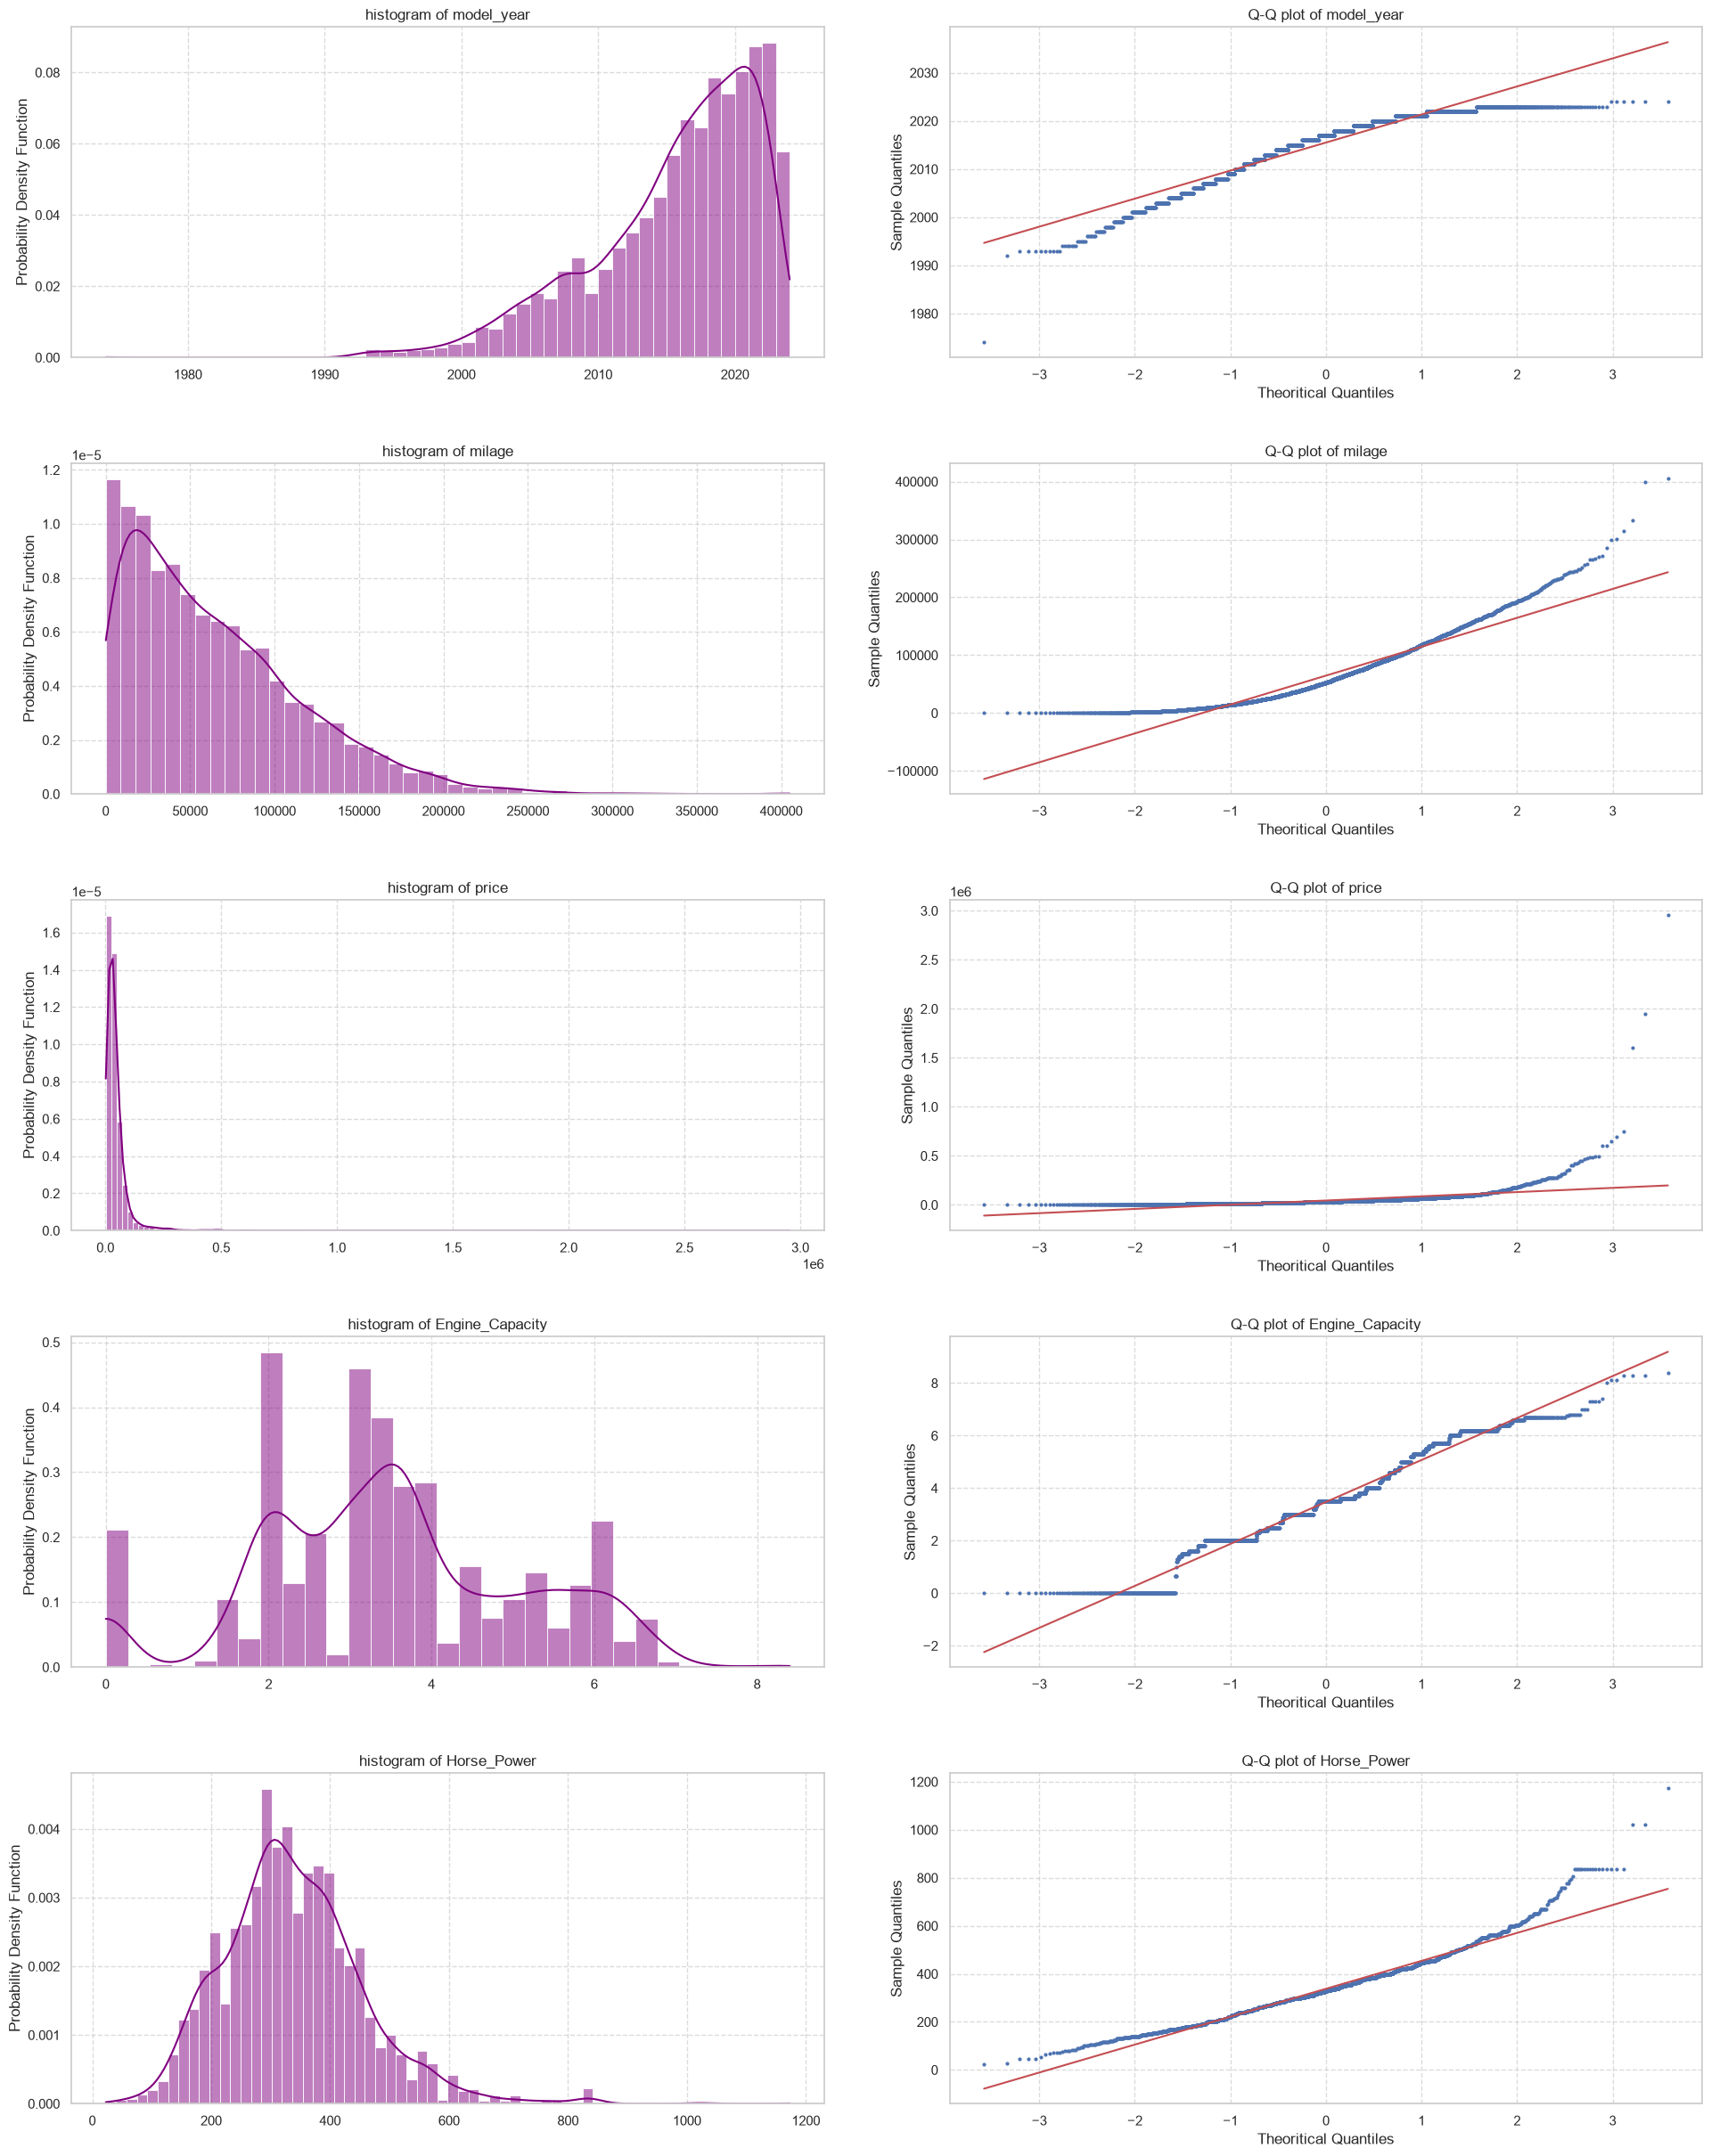

In [182]:
import scipy.stats as stats

num_cols = len(Numerical_Columns)
fig,axes = plt.subplots(num_cols,2,figsize=(20,num_cols*5))

for i , cols in enumerate(Numerical_Columns):
    sns.histplot(df[cols],kde=True, color='purple', ax=axes[i,0],stat='density',linewidth=0.6)
    axes[i,0].set_title(f"histogram of {cols}")
    axes[i,0].set_xlabel('')
    axes[i,0].set_ylabel('Probability Density Function')
    axes[i,0].grid(True, linestyle='--',alpha=0.7)

    stats.probplot(df[cols],plot=axes[i,1],dist='norm',fit=True)
    axes[i,1].set_title(f'Q-Q plot of {cols}')
    axes[i,1].set_xlabel('Theoritical Quantiles')
    axes[i,1].set_ylabel('Sample Quantiles')
    axes[i,1].grid(True, linestyle='--',alpha=0.7)
    axes[i,1].get_lines()[0].set_markersize(2.0)

plt.tight_layout(pad=3.0)
plt.show()

Strong Evidence to Statistical Test

In [183]:
def testing_normality(df,col):
    print("="*70)
    print(f'Normality Test for Columns: **{col}**')
    print('-'*70)

    #Shapiro-wilk Test
    stat,p= shapiro(df[col])
    print(f"shapiro-wilk test : stat={stat:.4f},p={p:.4f} → {'Normal' if p>0.05 else 'Not-Normal'}")

    #Anderson-Darling Test
    value=anderson(df[col])
    critical_value=value.critical_values[2]
    print(f"Anderson Darling Test : stat={value.statistic:.4f}, critical_value={critical_value:.4f} → {'Normal' if value.statistic<critical_value else'Not-Normal'}")

    print("\n")

for col in Numerical_Columns:
    testing_normality(df, col)

Normality Test for Columns: **model_year**
----------------------------------------------------------------------
shapiro-wilk test : stat=0.9090,p=0.0000 → Not-Normal
Anderson Darling Test : stat=102.2070, critical_value=0.7520 → Not-Normal


Normality Test for Columns: **milage**
----------------------------------------------------------------------
shapiro-wilk test : stat=0.9105,p=0.0000 → Not-Normal
Anderson Darling Test : stat=85.9013, critical_value=0.7520 → Not-Normal


Normality Test for Columns: **price**
----------------------------------------------------------------------
shapiro-wilk test : stat=0.2999,p=0.0000 → Not-Normal
Anderson Darling Test : stat=614.1549, critical_value=0.7520 → Not-Normal


Normality Test for Columns: **Engine_Capacity**
----------------------------------------------------------------------
shapiro-wilk test : stat=0.9709,p=0.0000 → Not-Normal
Anderson Darling Test : stat=36.6903, critical_value=0.7520 → Not-Normal


Normality Test for Columns: **

C:\Users\Dell\AppData\Local\Temp\ipykernel_29016\4003124153.py:11: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  value=anderson(df[col])


In [184]:
# if data normally distributed z-score else IQR


## Removing Outliers (if neccessary)

Functions to detect outliers using IQR method

In [185]:
def detect_outliers_using_iqr(data):
    outlier_mask=pd.Series(index=data.columns,dtype=bool)

    for col in data.columns:
        if col in Numerical_Columns:
            Q1=data[col].quantile(0.25)
            Q3=data[col].quantile(0.75)
            IQR=Q3-Q1
            lower_bound=Q1-1.5*IQR
            upper_bound=Q3+1.5*IQR
            col_outliers_mask=(
                (data[col]<lower_bound)|(data[col]>upper_bound)
            )
            outlier_mask[col]=col_outliers_mask.any()
    return outlier_mask
outliers_iqr_mask=detect_outliers_using_iqr(df)
print("\nOutliers detected using IQR is:\n")
for col,is_outlier in outliers_iqr_mask.items():
    print(f'{col} : {is_outlier}')



Outliers detected using IQR is:

brand : True
model : True
model_year : True
milage : True
fuel_type : True
engine : True
transmission : True
ext_col : True
int_col : True
accident : True
clean_title : True
price : True
Accident_Occured : True
Engine_Capacity : True
Horse_Power : True


Function to detect the outliers using Z-score method

In [186]:
def detect_outliers_using_zscore(data,threshold=3):
    outlier_mask = pd.Series(index=data.columns, dtype=bool)
    for col in data.columns:
        if col in Numerical_Columns:
            mean=np.mean(data[col])
            std_deviation=np.std(data[col])
            z_scores=np.abs((data[col]-mean)/std_deviation)
            col_outliers_mask=z_scores>threshold
            outlier_mask[col]=col_outliers_mask.any()
    return outlier_mask
    
outliers_zscore_mask=detect_outliers_using_zscore(df)
print("\nOutliers detected using z-score is:\n")    
for col,is_outlier in outliers_zscore_mask.items():
    print(f'{col}: {is_outlier}')


Outliers detected using z-score is:

brand: True
model: True
model_year: True
milage: True
fuel_type: True
engine: True
transmission: True
ext_col: True
int_col: True
accident: True
clean_title: True
price: True
Accident_Occured: True
Engine_Capacity: True
Horse_Power: True


### Fuctions to Remove Outliers using IQR Method

In [187]:
# def remove_outliers_iqr(data, Numerical_Columns):
#     cleaned_data=data.copy()

#     for col in Numerical_Columns:
#         Q1=cleaned_data[col].quantile(0.25)
#         Q3=cleaned_data[col].quantile(0.75)
#         IQR=Q3-Q1
#         lower_bound=Q1-1.5*IQR
#         upper_bound=Q3+1.5*IQR
#         cleaned_data=cleaned_data[
#             (cleaned_data[col]>=lower_bound)&
#             (cleaned_data[col]<=upper_bound)
#         ]
#     return cleaned_data

# cleaned_data_iqr=remove_outliers_iqr(df,Numerical_Columns)
# print("DataFrame after removing Outliers using IQR Method:")
# print(cleaned_data_iqr)


## Function to remove outliers using z-score method

In [188]:
# def remove_outliers_zscore(data,Numerical_Columns,threshold=3):
#     cleaned_data=data.copy()
#     for col in Numerical_Columns:
#         z_scores=zscore(cleaned_data[col])
#         cleaned_data=cleaned_data[abs(z_scores)<=threshold]
#     return cleaned_data

# cleaned_data_z_score=remove_outliers_zscore(df,Numerical_Columns)
# print("DataFrame after removing Outliers using Z-SCORE Method:")
# print(cleaned_data_z_score)

In [189]:
df.drop('engine', axis=1, inplace=True)

In [190]:
df.to_csv('../data/processed/Processed_Data.csv', index=False)

## Machine Learning Implementations

Loading DataSets

In [191]:
data=pd.read_csv('../data/processed/processed_Data.csv')


In [192]:
data.head()

,brand,model,model_year,milage,fuel_type,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occured,Engine_Capacity,Horse_Power
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7,300.000000
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8,386.324838
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,Automatic,Blue,Black,None reported,Unknown,54598.0,NO,3.5,392.527415
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5,354.000000
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,8-Speed Automatic,Glacier White Metallic,Black,None reported,Unknown,34999.0,NO,2.0,334.387743


Separating Features and Target Variable

In [193]:
TARGET = "price"
X = data.drop(columns=[TARGET])
y = data[TARGET]

low = y.quantile(0.01)
high = y.quantile(0.99)

mask = (y>= low) & (y <= high)
X = X[mask]
y = y[mask]

Train-Test-Split

In [194]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

In [195]:
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

low_card_cols = [c for c in cat_cols if X_train[c].nunique() <= 10]
mid_card_cols = [c for c in cat_cols if 10 < X_train[c].nunique() <= 50]
high_card_cols = [c for c in cat_cols if X_train[c].nunique() > 50]

print("Low:", low_card_cols)
print("Mid:", mid_card_cols)
print("High:", high_card_cols)

Low: ['fuel_type', 'accident', 'clean_title', 'Accident_Occured']
Mid: []
High: ['brand', 'model', 'transmission', 'ext_col', 'int_col']


In [196]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cols):
        self.cols =cols
        self.maps = {}

    def fit(self, X, y=None):
        for col in self.cols:
            self.maps[col] = X[col].value_counts(normalize=True)
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.cols:
            X[col] = X[col].map(self.maps[col]).fillna(0)
        return X

In [197]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols + high_card_cols),
        ('low_cat', OneHotEncoder(handle_unknown='ignore'), low_card_cols),
        ('mid_cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=1), mid_card_cols)
    ]
)

Ridge Regression

In [198]:
feature_selector = SelectFromModel(Lasso(alpha=0.001))
ridge_model = Pipeline(steps=[
    ('freq', FrequencyEncoder(high_card_cols)),
    ('preprocess', preprocessor),
    ('feature_select', feature_selector),
    ('regressor', TransformedTargetRegressor(
        regressor=Ridge(),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

In [199]:
param_grid = {
    'regressor__regressor__alpha': [0.1, 1, 5, 10, 20, 50]
}

grid = GridSearchCV(ridge_model, param_grid, cv=5, scoring='r2', n_jobs=-1)
grid.fit(X_train, y_train)

ridge_best_model = grid.best_estimator_
print("Best Alpha:", grid.best_params_)

Best Alpha: {'regressor__regressor__alpha': 50}


c:\Users\Dell\Documents\Artificial Intelligence\Machine Learning\Used_Cars_Price_Estimation\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.576058e+11, tolerance: 3.249e+08
  model = cd_fast.enet_coordinate_descent(


In [200]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    train_pred = model.predict(X_tr)
    test_pred = model.predict(X_te)

    print("\nTRAIN RESULTS")
    print("MAE:", mean_absolute_error(y_tr, train_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_tr, train_pred)))
    print("R2:", r2_score(y_tr, train_pred))

    print("\nTEST RESULTS")
    print("MAE:", mean_absolute_error(y_te, test_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_te, test_pred)))
    print("R2:", r2_score(y_te, test_pred))

In [201]:
evaluate(ridge_best_model, X_train, y_train, X_test, y_test)


TRAIN RESULTS
MAE: 11991.285588774448
RMSE: 24959.779881655195
R2: 0.4722397095402884

TEST RESULTS
MAE: 12403.81366193488
RMSE: 25797.02325819045
R2: 0.4821067661520383


## Decision Tree

In [202]:
Decistion_Tree_model=Pipeline(steps=[
    ('freq', FrequencyEncoder(high_card_cols)),
    ('preprocessor', preprocessor),
    ('regressor', TransformedTargetRegressor(
        regressor=DecisionTreeRegressor(max_depth=10, random_state=42),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])
Decistion_Tree_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('freq', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,cols,"['brand', 'model', ...]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('low_cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_thresho

In [203]:
evaluate(Decistion_Tree_model,X_train,y_train,X_test,y_test)


TRAIN RESULTS
MAE: 3948.869662162083
RMSE: 7983.7098874228595
R2: 0.9460036128742357

TEST RESULTS
MAE: 11017.18097975793
RMSE: 20511.043776556817
R2: 0.6726015871525204


In [204]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

# Parameter grid for Decision Tree
param_grid_dt= {
    'regressor__regressor__max_depth': [None, 5, 10, 20, 30],
    'regressor__regressor__min_samples_split': [2,5,10],
    'regressor__regressor__min_samples_leaf': [1,2,4],
    'regressor__regressor__max_features': [None,'sqrt','log2'],
    'regressor__regressor__criterion': ['squared_error', 'friedman_mse'],
}

grid_dt = GridSearchCV(
    Decistion_Tree_model,
    param_grid_dt,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=2
)

grid_dt.fit(X_train, y_train)

best_dt = grid_dt.best_estimator_

print("Best_Model:", best_dt)
print("Best_Params:", grid_dt.best_params_)

Fitting 5 folds for each of 270 candidates, totalling 1350 fits
Best_Model: Pipeline(steps=[('freq',
                 FrequencyEncoder(cols=['brand', 'model', 'transmission',
                                        'ext_col', 'int_col'])),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['model_year', 'milage',
                                                   'Engine_Capacity',
                                                   'Horse_Power', 'brand',
                                                   'model', 'transmission',
                                                   'ext_col', 'int_col']),
                                                 ('low_cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['fuel_type', 'accident',
                                                   'cl

c:\Users\Dell\Documents\Artificial Intelligence\Machine Learning\Used_Cars_Price_Estimation\env\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
675 fits failed out of a total of 1350.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Dell\Documents\Artificial Intelligence\Machine Learning\Used_Cars_Price_Estimation\env\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Dell\Documents\Artificial Intelligence\Machine Learning\Used_Cars_Price_Estimation\env\Lib\site-pac

In [205]:
evaluate(best_dt,X_train,y_train,X_test,y_test)


TRAIN RESULTS
MAE: 5800.083158322878
RMSE: 11731.91187457661
R2: 0.8834015459643899

TEST RESULTS
MAE: 10557.774637348253
RMSE: 18317.027245695685
R2: 0.738897500387222


Random Forest Algorithm

In [206]:
rf_model=Pipeline(steps=[
    ('freq',FrequencyEncoder(high_card_cols)),
    ('preprocessor',preprocessor),
    ('regressor',TransformedTargetRegressor(
        regressor=RandomForestRegressor(
            n_estimators=400,
            max_depth=None,
            random_state=42,
            n_jobs=-1
        ),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

rf_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('freq', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,cols,"['brand', 'model', ...]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('low_cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_thresho

In [207]:
evaluate(rf_model, X_train,y_train,X_test,y_test)


TRAIN RESULTS
MAE: 3210.5692031685035
RMSE: 7457.658868131181
R2: 0.952884887158854

TEST RESULTS
MAE: 8647.951654743096
RMSE: 16291.506684469374
R2: 0.7934507851018506


In [208]:
param_grid={
    'regressor__regressor__n_estimators':[100,200],
    'regressor__regressor__max_depth':[5,10,20],
    'regressor__regressor__min_samples_split':[2,5,10],
    'regressor__regressor__min_samples_leaf':[1,2,4],
    'regressor__regressor__max_features':['sqrt','log2']
}

grid=GridSearchCV(rf_model,param_grid,cv=5,scoring='neg_root_mean_squared_error',n_jobs=-1,verbose=2)
grid.fit(X_train,y_train)

best_rf=grid.best_estimator_
print("Best_Model",best_rf)
print("Best_Alpha",grid.best_params_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best_Model Pipeline(steps=[('freq',
                 FrequencyEncoder(cols=['brand', 'model', 'transmission',
                                        'ext_col', 'int_col'])),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['model_year', 'milage',
                                                   'Engine_Capacity',
                                                   'Horse_Power', 'brand',
                                                   'model', 'transmission',
                                                   'ext_col', 'int_col']),
                                                 ('low_cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['fuel_type', 'accident',
                                                   'clea

In [209]:
evaluate(best_rf, X_train,y_train,X_test,y_test)


TRAIN RESULTS
MAE: 3533.4326098875854
RMSE: 8289.5504600079
R2: 0.9417873771988794

TEST RESULTS
MAE: 9324.15942637805
RMSE: 18883.329285153766
R2: 0.7225030721693696


XGBOOST ALgorithm

In [210]:
from xgboost import XGBRegressor

In [211]:
xg_model=Pipeline(steps=[
    ('freq',FrequencyEncoder(high_card_cols)),
    ('preprocessor',preprocessor),
    ('regressor',TransformedTargetRegressor(
        regressor=XGBRegressor(
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

xg_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('freq', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,cols,"['brand', 'model', ...]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('low_cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_thresho

In [212]:
evaluate(xg_model,X_train,y_train,X_test,y_test)


TRAIN RESULTS
MAE: 1823.0833009231922
RMSE: 3273.2441419265438
R2: 0.9909236338666889

TEST RESULTS
MAE: 7877.052722374868
RMSE: 14050.649040230634
R2: 0.8463637073797282


In [213]:
param_grid={
    'regressor__regressor__n_estimators':[100,200,300,500],
    'regressor__regressor__max_depth':[3,5,7,9,10],
    'regressor__regressor__learning_rate':[0.01,0.05,0.1,1],
    'regressor__regressor__subsample':[0.7,0.8,0.9,1.0]
}

grid=GridSearchCV(xg_model,param_grid,cv=5,scoring='r2',n_jobs=-1,verbose=1)
grid.fit(X_train,y_train)

best_rf=grid.best_estimator_
print(f"Best params: {grid.best_params_}")
print(f"Best CV R2: {grid.best_score_:.4f}")

Fitting 5 folds for each of 320 candidates, totalling 1600 fits
Best params: {'regressor__regressor__learning_rate': 0.05, 'regressor__regressor__max_depth': 5, 'regressor__regressor__n_estimators': 500, 'regressor__regressor__subsample': 0.8}
Best CV R2: 0.8353


In [214]:
evaluate(best_rf,X_train,y_train,X_test,y_test)


TRAIN RESULTS
MAE: 3352.8116605891737
RMSE: 6068.087617720609
R2: 0.9688068743932703

TEST RESULTS
MAE: 7341.851188840705
RMSE: 13468.959958633044
R2: 0.8588213026704007


## Save the Model

In [219]:
os.makedirs('ML_Models',exist_ok=True)

In [221]:
import joblib
MODEL_PATH=r"NoteBooks\ML_Models\best_xgboost.pkl"
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
joblib.dump(xg_model,MODEL_PATH)
print(f"\n Model saved to: {MODEL_PATH}\n")


 Model saved to: NoteBooks\ML_Models\best_xgboost.pkl

